# NeuroMed — Brain Tumor Prediction: Model Training Pipeline

**Prerequisites:** Upload `Brain_Tumor_Cleaned_ENCODED.csv` before running.

In [1]:
!pip install -q xgboost lightgbm optuna shap

import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns, warnings, joblib, json, os, random

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
TARGET_SENSITIVITY = 0.90

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    cross_validate, learning_curve
)
from sklearn.preprocessing import RobustScaler
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score,
    matthews_corrcoef, brier_score_loss
)
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# FrozenEstimator — replaces cv='prefit' in new scikit-learn
try:
    from sklearn.frozen import FrozenEstimator
    _FROZEN_AVAILABLE = True
except ImportError:
    _FROZEN_AVAILABLE = False  # older sklearn uses cv='prefit'

import xgboost as xgb, lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import shap

warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid', palette='viridis')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
print('All libraries imported successfully.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 28.7 MB/s eta 0:00:00
All libraries imported successfully.


In [2]:
df_raw = pd.read_csv('Brain_Tumor_Cleaned_ENCODED.csv')

print('=' * 70)
print('DATASET OVERVIEW (RAW)')
print('=' * 70)
print(f'Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
for val, cnt in df_raw['Brain_Tumor_Present'].value_counts().sort_index().items():
    label = 'Tumor Present' if val == 1 else 'No Tumor'
    print(f'  {val} ({label}): {cnt:,} ({cnt/len(df_raw)*100:.1f}%)')

DATASET OVERVIEW (RAW)
Shape: 217,585 rows x 26 columns
  0 (No Tumor): 92,754 (42.6%)
  1 (Tumor Present): 124,831 (57.4%)


## Data Findings

Key facts verified in this dataset:

1. **Artificial prevalence:** 57.4% 'Tumor Present' — far above real-world ~1-5%. Predicted probabilities **do not reflect real-world risk**.
2. **Leakage columns:** `Tumor_Type` and `Treatment_Received` are 0 for every 'No Tumor' row — dropped.
3. **BP / chronic illness carry no signal:** AUC ≈ 0.50 for these columns.
4. **Derived columns are redundant:** Symptom_Count, scores, MAP, BP_Category are computed from other columns.
5. **Symptom ceiling:** The 12 symptom columns give ~0.92 ROC-AUC. More complex models do not meaningfully improve this.
6. **BP_Category coding error in CSV:** Recomputed below with correct ACC/AHA rule.
7. **Duplicate rows:** ~3,367 duplicate-feature rows — removed before splitting.

In [3]:
df = df_raw.copy()

# Correct BP_Category (ACC/AHA 2017)
def correct_bp_category(row):
    s, d = row['Systolic_BP'], row['Diastolic_BP']
    if s >= 140 or d >= 90:   return 3  # Stage 2
    if s >= 130 or d >= 80:   return 2  # Stage 1
    if s >= 120:               return 1  # Elevated
    return 0                             # Normal

df['BP_Category'] = df.apply(correct_bp_category, axis=1)
print('BP_Category recomputed with correct ACC/AHA rule.')

# Drop leakage
TARGET = 'Brain_Tumor_Present'
df = df.drop(columns=['Tumor_Type', 'Treatment_Received'], errors='ignore')
print('Dropped leakage columns: Tumor_Type, Treatment_Received')

# Remove duplicates on feature columns
feat_cols_all = [c for c in df.columns if c != TARGET]
n_before = len(df)
df = df.drop_duplicates(subset=feat_cols_all, keep='first').reset_index(drop=True)
print(f'Rows before: {n_before:,}  |  After de-duplication: {len(df):,}  '
      f'(removed {n_before - len(df):,})')
for val, cnt in df[TARGET].value_counts().sort_index().items():
    print(f'  {val}: {cnt:,} ({cnt/len(df)*100:.1f}%)')

BP_Category recomputed with correct ACC/AHA rule.
Dropped leakage columns: Tumor_Type, Treatment_Received
Rows before: 217,585  |  After de-duplication: 214,218  (removed 3,367)
  0: 91,446 (42.7%)
  1: 122,772 (57.3%)


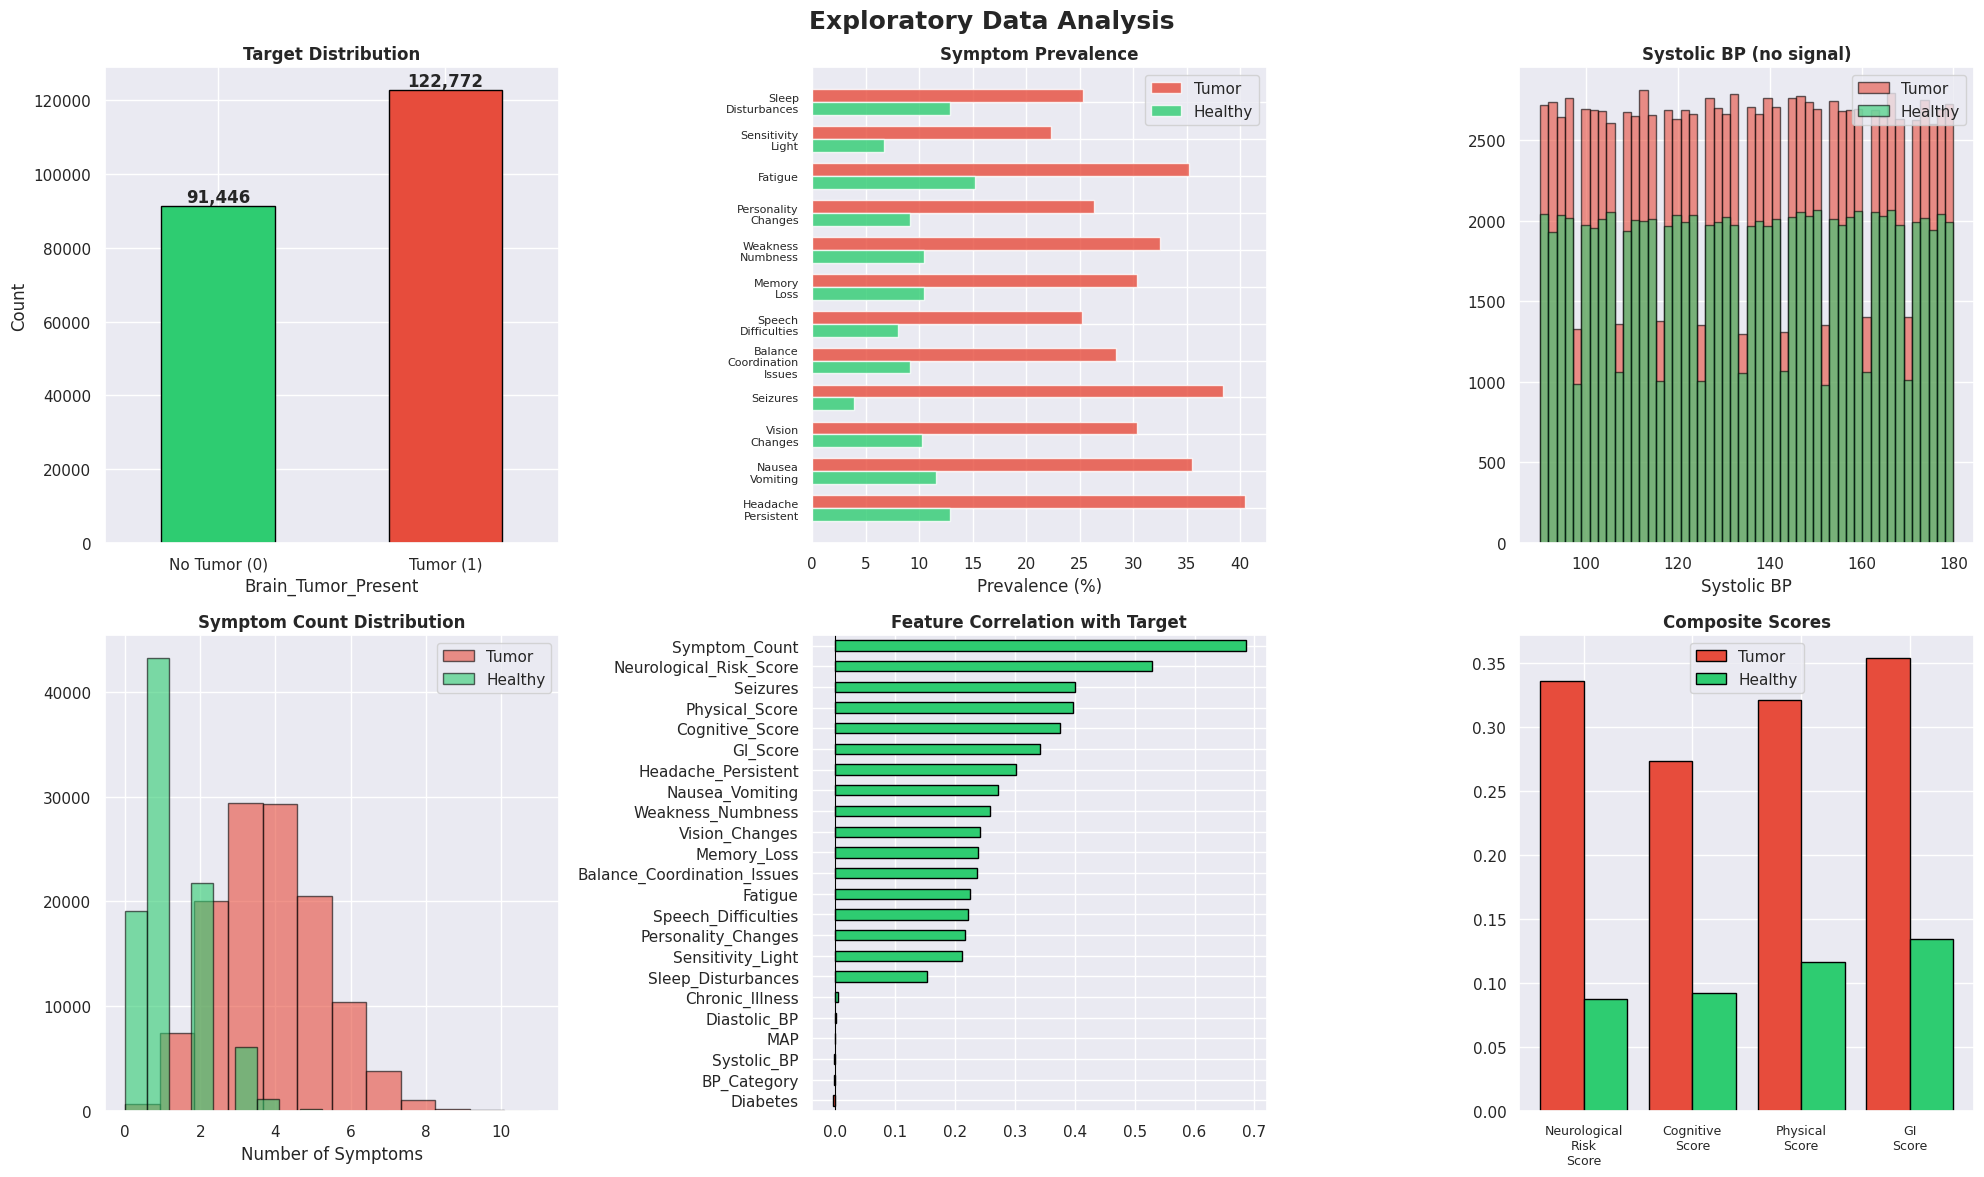

EDA saved.


In [4]:
SYMPTOM_COLS = [
    'Headache_Persistent', 'Nausea_Vomiting', 'Vision_Changes', 'Seizures',
    'Balance_Coordination_Issues', 'Speech_Difficulties', 'Memory_Loss',
    'Weakness_Numbness', 'Personality_Changes', 'Fatigue',
    'Sensitivity_Light', 'Sleep_Disturbances'
]
ALL_FEATURE_COLS = [
    'Chronic_Illness', 'Diabetes',
    'Systolic_BP', 'Diastolic_BP', 'MAP', 'BP_Category',
    'Headache_Persistent', 'Nausea_Vomiting', 'Vision_Changes', 'Seizures',
    'Balance_Coordination_Issues', 'Speech_Difficulties', 'Memory_Loss',
    'Weakness_Numbness', 'Personality_Changes', 'Fatigue',
    'Sensitivity_Light', 'Sleep_Disturbances',
    'Symptom_Count', 'Neurological_Risk_Score', 'Cognitive_Score',
    'Physical_Score', 'GI_Score'
]
CONTINUOUS_COLS = ['Systolic_BP', 'Diastolic_BP', 'MAP',
                   'Symptom_Count', 'Neurological_Risk_Score',
                   'Cognitive_Score', 'Physical_Score', 'GI_Score']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Exploratory Data Analysis', fontsize=18, fontweight='bold')

# 1. Target Distribution — sort_index() so bar order = label order
ax = axes[0, 0]
vc = df['Brain_Tumor_Present'].value_counts().sort_index()  # 0 first, 1 second
vc.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Target Distribution', fontweight='bold')
ax.set_xticklabels(['No Tumor (0)', 'Tumor (1)'], rotation=0)
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontweight='bold')

# 2. Symptom Prevalence
ax = axes[0, 1]
tumor   = df[df[TARGET]==1][SYMPTOM_COLS].mean() * 100
healthy = df[df[TARGET]==0][SYMPTOM_COLS].mean() * 100
x = np.arange(len(SYMPTOM_COLS)); w = 0.35
ax.barh(x + w/2, tumor.values,   w, label='Tumor',   color='#e74c3c', alpha=0.8)
ax.barh(x - w/2, healthy.values, w, label='Healthy', color='#2ecc71', alpha=0.8)
ax.set_yticks(x)
ax.set_yticklabels([s.replace('_', '\n') for s in SYMPTOM_COLS], fontsize=8)
ax.set_xlabel('Prevalence (%)'); ax.legend()
ax.set_title('Symptom Prevalence', fontweight='bold')

# 3. BP (no signal)
ax = axes[0, 2]
df[df[TARGET]==1]['Systolic_BP'].hist(ax=ax, bins=50, alpha=0.6,
    label='Tumor', color='#e74c3c', edgecolor='black')
df[df[TARGET]==0]['Systolic_BP'].hist(ax=ax, bins=50, alpha=0.6,
    label='Healthy', color='#2ecc71', edgecolor='black')
ax.set_title('Systolic BP (no signal)', fontweight='bold')
ax.set_xlabel('Systolic BP'); ax.legend()

# 4. Symptom Count
ax = axes[1, 0]
df[df[TARGET]==1]['Symptom_Count'].hist(ax=ax, bins=12, alpha=0.6,
    label='Tumor', color='#e74c3c', edgecolor='black')
df[df[TARGET]==0]['Symptom_Count'].hist(ax=ax, bins=12, alpha=0.6,
    label='Healthy', color='#2ecc71', edgecolor='black')
ax.set_title('Symptom Count Distribution', fontweight='bold')
ax.set_xlabel('Number of Symptoms'); ax.legend()

# 5. Feature Correlation with Target
ax = axes[1, 1]
corr = df.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
corr.plot(kind='barh', ax=ax,
          color=['#e74c3c' if v < 0 else '#2ecc71' for v in corr.values],
          edgecolor='black')
ax.set_title('Feature Correlation with Target', fontweight='bold')
ax.axvline(x=0, color='black', linewidth=0.8)

# 6. Composite Scores
ax = axes[1, 2]
sc = ['Neurological_Risk_Score', 'Cognitive_Score', 'Physical_Score', 'GI_Score']
ts = df[df[TARGET]==1][sc].mean()
hs = df[df[TARGET]==0][sc].mean()
x2 = np.arange(len(sc))
ax.bar(x2-0.2, ts.values, 0.4, label='Tumor',   color='#e74c3c', edgecolor='black')
ax.bar(x2+0.2, hs.values, 0.4, label='Healthy', color='#2ecc71', edgecolor='black')
ax.set_xticks(x2)
ax.set_xticklabels([s.replace('_', '\n') for s in sc], fontsize=9); ax.legend()
ax.set_title('Composite Scores', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print('EDA saved.')

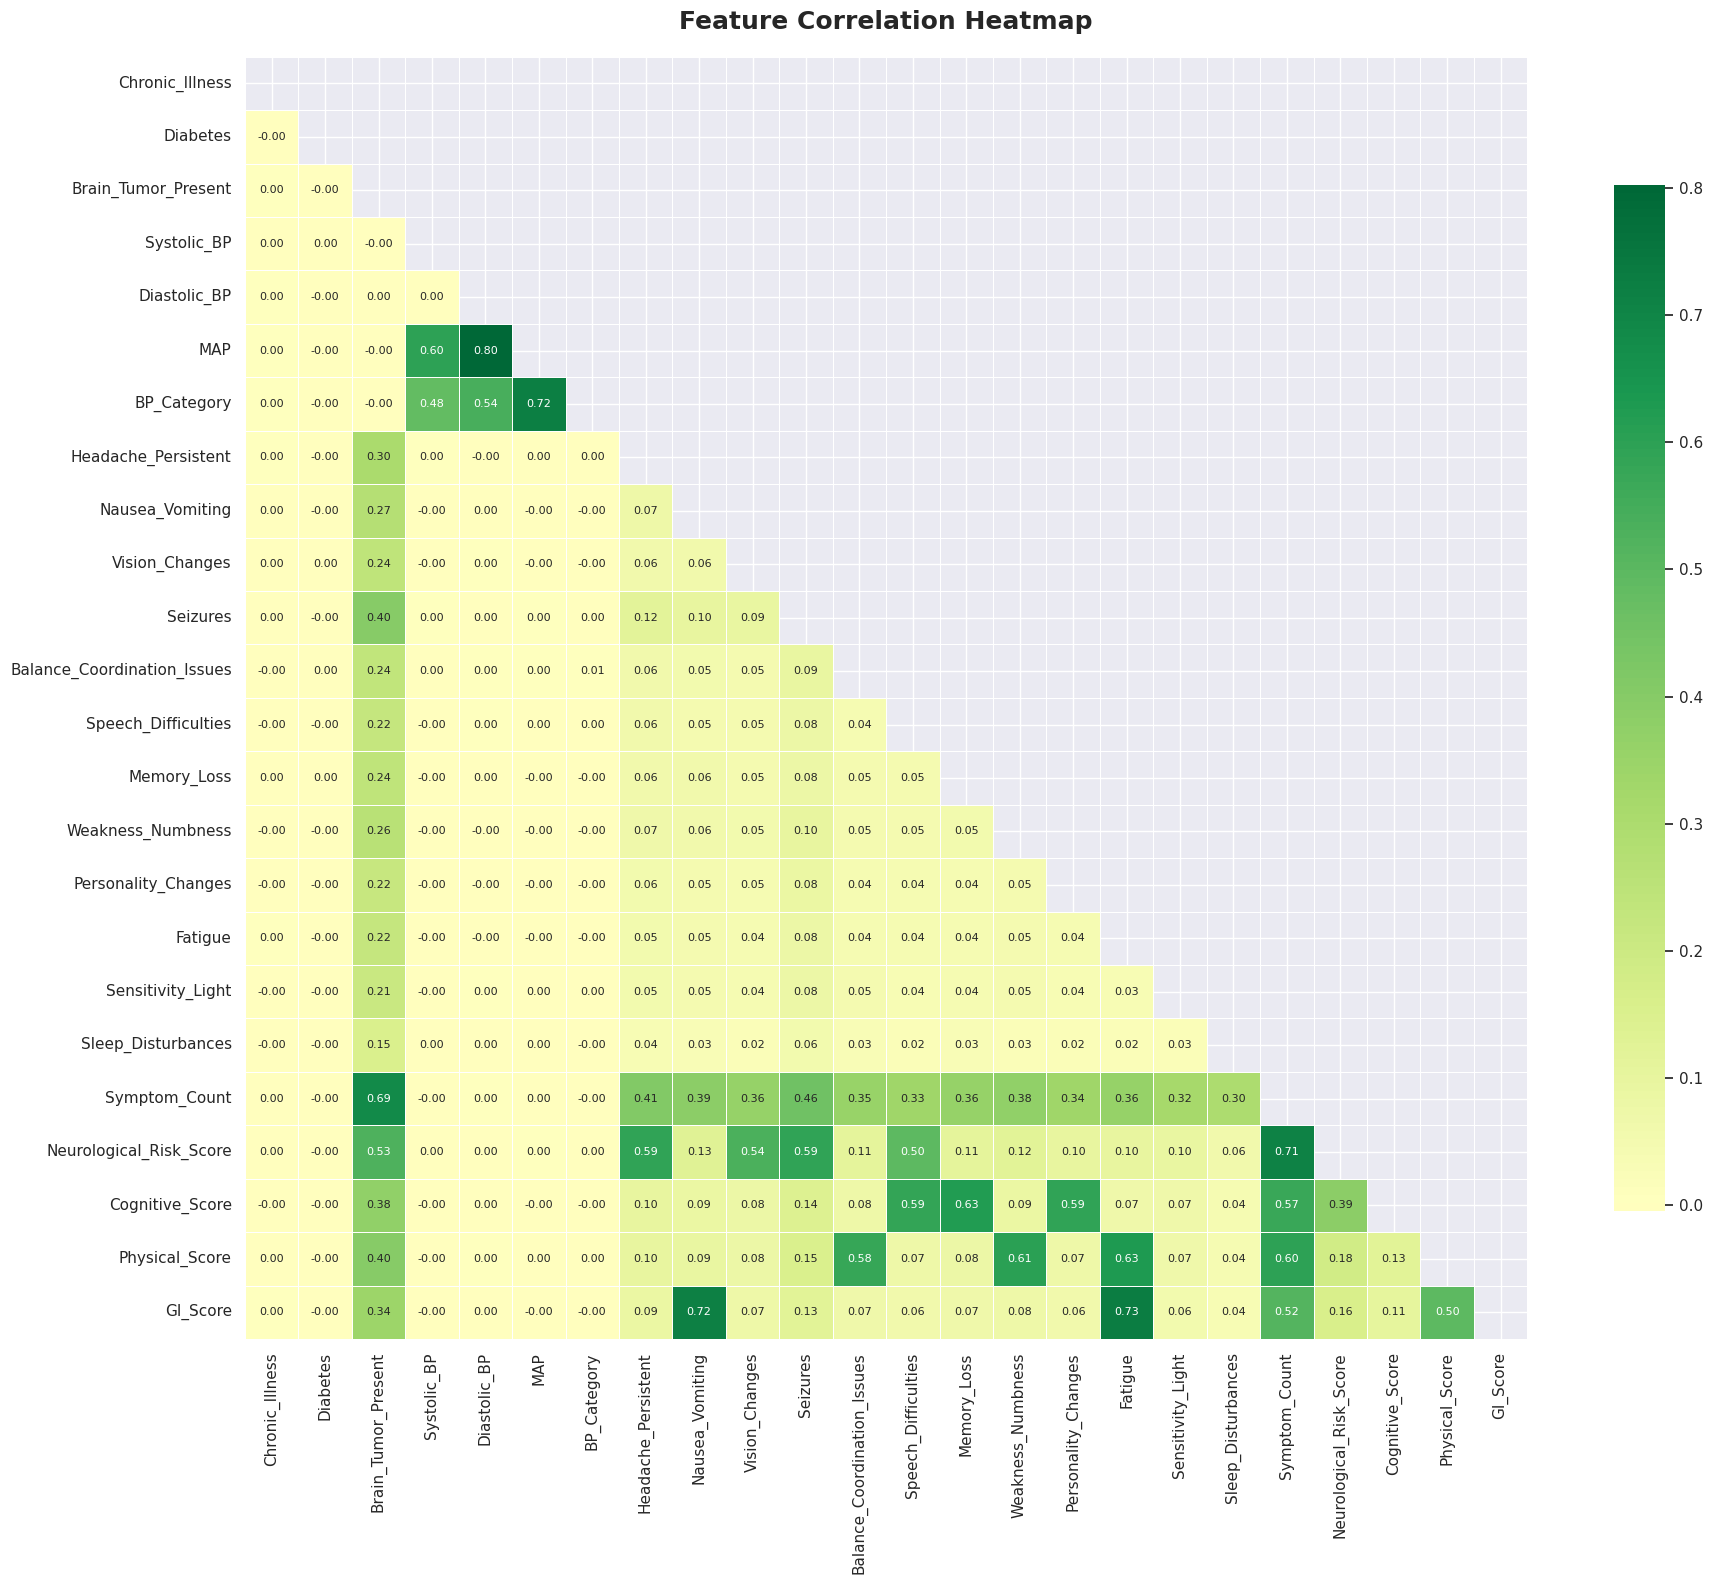

In [5]:
plt.figure(figsize=(20, 16))
cm_mat = df.corr(numeric_only=True)
mask   = np.triu(np.ones_like(cm_mat, dtype=bool))
sns.heatmap(cm_mat, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, annot_kws={'size': 8})
plt.title('Feature Correlation Heatmap', fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# ── 70 / 15 / 15 stratified split ──
X_all = df[ALL_FEATURE_COLS]
y     = df[TARGET]

# 15% test
X_trainval_all, X_test_all, y_trainval, y_test = train_test_split(
    X_all, y, test_size=0.15, random_state=RANDOM_SEED, stratify=y
)
# 15% val from remaining 85%  → 0.176 × 0.85 ≈ 0.15 of total
X_train_all, X_val_all, y_train, y_val = train_test_split(
    X_trainval_all, y_trainval, test_size=0.176,
    random_state=RANDOM_SEED, stratify=y_trainval
)

X_train_sym    = X_train_all[SYMPTOM_COLS]
X_val_sym      = X_val_all[SYMPTOM_COLS]
X_test_sym     = X_test_all[SYMPTOM_COLS]
X_trainval_sym = X_trainval_all[SYMPTOM_COLS]

print(f'Train:      {len(X_train_all):,}  '
      f'Val: {len(X_val_all):,}  '
      f'Test: {len(X_test_all):,}')

# ── Scaling (fit ONLY on X_train_all, transform others) ──
scaler_all = RobustScaler()

def scale(df_in, scaler, cont, fit=False):
    out  = df_in.copy().astype(float)
    cols = [c for c in cont if c in out.columns]
    if cols:
        out[cols] = scaler.fit_transform(out[cols]) if fit else scaler.transform(out[cols])
    return out

X_tr_all_sc  = scale(X_train_all,    scaler_all, CONTINUOUS_COLS, fit=True)
X_vl_all_sc  = scale(X_val_all,      scaler_all, CONTINUOUS_COLS)
X_te_all_sc  = scale(X_test_all,     scaler_all, CONTINUOUS_COLS)
X_tv_all_sc  = scale(X_trainval_all, scaler_all, CONTINUOUS_COLS)

# Symptom columns are binary — no scaling needed
X_tr_sym_sc  = X_train_sym.copy().astype(float)
X_vl_sym_sc  = X_val_sym.copy().astype(float)
X_te_sym_sc  = X_test_sym.copy().astype(float)
X_tv_sym_sc  = X_trainval_sym.copy().astype(float)

# Save scaler
joblib.dump(scaler_all, 'scaler_all.pkl')
joblib.dump(list(ALL_FEATURE_COLS), 'feature_names_all.pkl')
joblib.dump(list(SYMPTOM_COLS),     'feature_names_sym.pkl')
joblib.dump(CONTINUOUS_COLS,        'continuous_cols.pkl')
print('Scaler and metadata saved.')

Train:      150,038  Val: 32,047  Test: 32,133
Scaler and metadata saved.


In [7]:
print('=' * 70)
print('FEATURE SET EXPERIMENT — 5-fold CV on training data only')
print('=' * 70)

cv_fs  = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
ref_m  = LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)

roc_all = cross_val_score(ref_m, X_tv_all_sc,  y_trainval,
                          cv=cv_fs, scoring='roc_auc', n_jobs=-1)
roc_sym = cross_val_score(ref_m, X_tv_sym_sc,  y_trainval,
                          cv=cv_fs, scoring='roc_auc', n_jobs=-1)

print(f'  Set A — all 23 features:     ROC-AUC = {roc_all.mean():.4f} +/- {roc_all.std():.4f}')
print(f'  Set B — 12 symptom columns:  ROC-AUC = {roc_sym.mean():.4f} +/- {roc_sym.std():.4f}')

diff = roc_all.mean() - roc_sym.mean()
print(f'  Difference A-B: {diff:.4f}')

if diff <= 0.002:
    CHOSEN_FS   = 'B_symptom'
    X_tr        = X_tr_sym_sc
    X_vl        = X_vl_sym_sc
    X_te        = X_te_sym_sc
    X_tv        = X_tv_sym_sc
    FINAL_FEATURES = list(SYMPTOM_COLS)
    FEAT_SCALER    = None
    print('  => Set B chosen (simpler, within 0.002 ROC-AUC).')
else:
    CHOSEN_FS   = 'A_all'
    X_tr        = X_tr_all_sc
    X_vl        = X_vl_all_sc
    X_te        = X_te_all_sc
    X_tv        = X_tv_all_sc
    FINAL_FEATURES = list(ALL_FEATURE_COLS)
    FEAT_SCALER    = scaler_all
    print(f'  => Set A chosen (better by {diff:.4f}).')

print(f'  Final feature set: {CHOSEN_FS}  ({len(FINAL_FEATURES)} features)')

FEATURE SET EXPERIMENT — 5-fold CV on training data only
  Set A — all 23 features:     ROC-AUC = 0.9265 +/- 0.0016
  Set B — 12 symptom columns:  ROC-AUC = 0.9265 +/- 0.0016
  Difference A-B: -0.0000
  => Set B chosen (simpler, within 0.002 ROC-AUC).
  Final feature set: B_symptom  (12 features)


In [8]:
print('=' * 70)
print('BASELINE MODEL COMPARISON — CV ROC-AUC on training data')
print('=' * 70)

models_def = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_SEED),
    'Random Forest':       RandomForestClassifier(
        n_estimators=200, max_depth=12, random_state=RANDOM_SEED, n_jobs=-1),
    'XGBoost':             xgb.XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        random_state=RANDOM_SEED, n_jobs=-1, eval_metric='logloss'),
    'LightGBM':            lgb.LGBMClassifier(
        n_estimators=200, max_depth=8, learning_rate=0.1,
        random_state=RANDOM_SEED, n_jobs=-1, verbose=-1),
    'Gradient Boosting':   GradientBoostingClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1,
        random_state=RANDOM_SEED),
    'KNN':                 KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    'Neural Network (MLP)':MLPClassifier(
        hidden_layer_sizes=(128, 64), max_iter=200,
        random_state=RANDOM_SEED, early_stopping=True),
}

cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
base_res = {}
for name, m in models_def.items():
    r = cross_validate(m, X_tv, y_trainval, cv=cv_b,
                       scoring={'roc_auc':'roc_auc','f1':'f1',
                                'neg_log_loss':'neg_log_loss'}, n_jobs=-1)
    base_res[name] = {
        'roc_auc': r['test_roc_auc'].mean(),
        'roc_std': r['test_roc_auc'].std(),
        'f1':      r['test_f1'].mean(),
        'log_loss':-r['test_neg_log_loss'].mean(),
    }

print(f"\n{'Model':<25} {'ROC-AUC':>10} {'Std':>8} {'F1':>8} {'LogLoss':>10}")
print('-' * 63)
for n, r in sorted(base_res.items(), key=lambda x: -x[1]['roc_auc']):
    print(f"{n:<25} {r['roc_auc']:>10.4f} {r['roc_std']:>8.4f} "
          f"{r['f1']:>8.4f} {r['log_loss']:>10.4f}")

BASELINE MODEL COMPARISON — CV ROC-AUC on training data

Model                        ROC-AUC      Std       F1    LogLoss
---------------------------------------------------------------
Logistic Regression           0.9265   0.0016   0.8624     0.3359
Neural Network (MLP)          0.9260   0.0015   0.8622     0.3373
Gradient Boosting             0.9260   0.0016   0.8629     0.3373
XGBoost                       0.9258   0.0016   0.8627     0.3376
LightGBM                      0.9257   0.0016   0.8628     0.3379
Random Forest                 0.9249   0.0016   0.8627     0.3915
KNN                           0.9045   0.0032   0.8576     1.3007


In [9]:
print('=' * 70)
print('OPTUNA HYPERPARAMETER TUNING')
print('Tuning on stratified 40k-row subsample of training data.')
print('Trials per model: LR/XGB/LGBM=30, RF/GBM/KNN/MLP=10')
print('=' * 70)

# Subsample for speed (stratified, 40k max)
N_TUNE   = min(40_000, len(X_tv))
sub_idx  = X_tv.groupby(y_trainval).apply(
    lambda g: g.sample(int(N_TUNE * len(g) / len(X_tv)),
                       random_state=RANDOM_SEED)
).index.get_level_values(1)
X_tune   = X_tv.loc[sub_idx]
y_tune   = y_trainval.loc[sub_idx]
print(f'Tuning subsample size: {len(X_tune):,}')

CV_OPT = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)

# Trials budget per model
TRIALS = {
    'Logistic Regression': 30, 'XGBoost': 30, 'LightGBM': 30,
    'Random Forest': 10, 'Gradient Boosting': 10, 'KNN': 10, 'Neural Network (MLP)': 10
}

def make_objective(name, X_data, y_data):
    def objective(trial):
        if name == 'Logistic Regression':
            m = LogisticRegression(
                C=trial.suggest_float('C', 1e-4, 100.0, log=True),
                max_iter=2000, random_state=RANDOM_SEED)
        elif name == 'Random Forest':
            m = RandomForestClassifier(
                n_estimators=trial.suggest_int('n_estimators', 50, 300),
                max_depth=trial.suggest_int('max_depth', 3, 15),
                min_samples_split=trial.suggest_int('min_samples_split', 2, 10),
                random_state=RANDOM_SEED, n_jobs=-1)
        elif name == 'XGBoost':
            m = xgb.XGBClassifier(
                n_estimators=trial.suggest_int('n_estimators', 50, 300),
                max_depth=trial.suggest_int('max_depth', 3, 8),
                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                subsample=trial.suggest_float('subsample', 0.6, 1.0),
                colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
                random_state=RANDOM_SEED, n_jobs=-1, eval_metric='logloss')
        elif name == 'LightGBM':
            m = lgb.LGBMClassifier(
                n_estimators=trial.suggest_int('n_estimators', 50, 300),
                max_depth=trial.suggest_int('max_depth', 3, 8),
                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                subsample=trial.suggest_float('subsample', 0.6, 1.0),
                colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
                random_state=RANDOM_SEED, n_jobs=-1, verbose=-1)
        elif name == 'Gradient Boosting':
            m = GradientBoostingClassifier(
                n_estimators=trial.suggest_int('n_estimators', 50, 300),
                max_depth=trial.suggest_int('max_depth', 3, 7),
                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                subsample=trial.suggest_float('subsample', 0.6, 1.0),
                random_state=RANDOM_SEED)
        elif name == 'KNN':
            m = KNeighborsClassifier(
                n_neighbors=trial.suggest_int('n_neighbors', 3, 25),
                weights=trial.suggest_categorical('weights', ['uniform', 'distance']),
                n_jobs=-1)
        elif name == 'Neural Network (MLP)':
            m = MLPClassifier(
                hidden_layer_sizes=trial.suggest_categorical(
                    'hidden_layer_sizes', [(64,), (128, 64)]),
                alpha=trial.suggest_float('alpha', 1e-4, 1e-1, log=True),
                max_iter=200, random_state=RANDOM_SEED, early_stopping=True)
        return cross_val_score(m, X_data, y_data,
                               cv=CV_OPT, scoring='roc_auc', n_jobs=-1).mean()
    return objective

tuned_params = {}
for name in models_def:
    n = TRIALS[name]
    print(f'\nOptimising {name} ({n} trials)...')
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
    study.optimize(make_objective(name, X_tune, y_tune),
                   n_trials=n, show_progress_bar=True)
    tuned_params[name] = study.best_params
    print(f'  Best ROC-AUC: {study.best_value:.4f}  Params: {study.best_params}')

print('\nTuning complete.')

OPTUNA HYPERPARAMETER TUNING
Tuning on stratified 40k-row subsample of training data.
Trials per model: LR/XGB/LGBM=30, RF/GBM/KNN/MLP=10
Tuning subsample size: 39,999

Optimising Logistic Regression (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

  Best ROC-AUC: 0.9256  Params: {'C': 0.03469124992034071}

Optimising Random Forest (10 trials)...


  0%|          | 0/10 [00:00<?, ?it/s]

  Best ROC-AUC: 0.9239  Params: {'n_estimators': 179, 'max_depth': 10, 'min_samples_split': 2}

Optimising XGBoost (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

  Best ROC-AUC: 0.8729  Params: {'n_neighbors': 22, 'weights': 'uniform'}

Optimising Neural Network (MLP) (10 trials)...


  0%|          | 0/10 [00:00<?, ?it/s]

  Best ROC-AUC: 0.9253  Params: {'hidden_layer_sizes': (64,), 'alpha': 0.0812324508558869}

Tuning complete.


In [10]:
print('=' * 70)
print('TUNED MODEL CV EVALUATION (training data, 5-fold)')
print('=' * 70)

def build_model(name, params):
    if name == 'Logistic Regression':
        return LogisticRegression(**params, max_iter=2000, random_state=RANDOM_SEED)
    elif name == 'Random Forest':
        return RandomForestClassifier(**params, random_state=RANDOM_SEED, n_jobs=-1)
    elif name == 'XGBoost':
        return xgb.XGBClassifier(**params, random_state=RANDOM_SEED,
                                  n_jobs=-1, eval_metric='logloss')
    elif name == 'LightGBM':
        return lgb.LGBMClassifier(**params, random_state=RANDOM_SEED,
                                   n_jobs=-1, verbose=-1)
    elif name == 'Gradient Boosting':
        return GradientBoostingClassifier(**params, random_state=RANDOM_SEED)
    elif name == 'KNN':
        return KNeighborsClassifier(**params, n_jobs=-1)
    elif name == 'Neural Network (MLP)':
        return MLPClassifier(**params, max_iter=200,
                              random_state=RANDOM_SEED, early_stopping=True)

cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
tuned_cv  = {}

for name in models_def:
    m = build_model(name, tuned_params[name])
    r = cross_validate(m, X_tv, y_trainval, cv=cv_final,
                       scoring={'roc_auc':'roc_auc', 'f1':'f1',
                                'neg_log_loss':'neg_log_loss',
                                'precision':'precision', 'recall':'recall'}, n_jobs=-1)
    tuned_cv[name] = {
        'roc_auc':  r['test_roc_auc'].mean(),
        'roc_std':  r['test_roc_auc'].std(),
        'f1':       r['test_f1'].mean(),
        'log_loss': -r['test_neg_log_loss'].mean(),
        'precision':r['test_precision'].mean(),
        'recall':   r['test_recall'].mean(),
    }

print(f"\n{'Model':<25} {'ROC-AUC':>10} {'Std':>8} {'F1':>8} {'LogLoss':>10}")
print('-' * 63)
for n, r in sorted(tuned_cv.items(), key=lambda x: -x[1]['roc_auc']):
    print(f"{n:<25} {r['roc_auc']:>10.4f} {r['roc_std']:>8.4f} "
          f"{r['f1']:>8.4f} {r['log_loss']:>10.4f}")

# ── Model selection ──
print('\n' + '=' * 70)
print('MODEL SELECTION (CV only, test set not touched)')
print('=' * 70)

best_name = max(tuned_cv, key=lambda x: tuned_cv[x]['roc_auc'])
best_roc  = tuned_cv[best_name]['roc_auc']
lr_roc    = tuned_cv['Logistic Regression']['roc_auc']

print(f'  Best model by CV ROC-AUC: {best_name}  ({best_roc:.4f})')
print(f'  Logistic Regression:      {lr_roc:.4f}')

if best_roc - lr_roc <= 0.002:
    SEL_NAME = 'Logistic Regression'
    print('  => Logistic Regression selected (simpler, within 0.002).')
else:
    SEL_NAME = best_name
    print(f'  => {SEL_NAME} selected.')

print(f'  SELECTED MODEL: {SEL_NAME}')

TUNED MODEL CV EVALUATION (training data, 5-fold)

Model                        ROC-AUC      Std       F1    LogLoss
---------------------------------------------------------------
Logistic Regression           0.9265   0.0016   0.8624     0.3360
Neural Network (MLP)          0.9262   0.0018   0.8619     0.3365
XGBoost                       0.9262   0.0016   0.8625     0.3364
LightGBM                      0.9261   0.0016   0.8625     0.3364
Gradient Boosting             0.9260   0.0016   0.8623     0.3372
Random Forest                 0.9251   0.0015   0.8625     0.3464
KNN                           0.9205   0.0016   0.8620     0.5805

MODEL SELECTION (CV only, test set not touched)
  Best model by CV ROC-AUC: Logistic Regression  (0.9265)
  Logistic Regression:      0.9265
  => Logistic Regression selected (simpler, within 0.002).
  SELECTED MODEL: Logistic Regression


FINAL MODEL: Logistic Regression
CALIBRATION SETUP
Base model fitted on X_train (150,038 rows).
Using FrozenEstimator (sklearn >= 1.8 mode).
Calibration complete. Checking type of inner estimator:
  type(cal_clf.calibrated_classifiers_[0].estimator) = FrozenEstimator


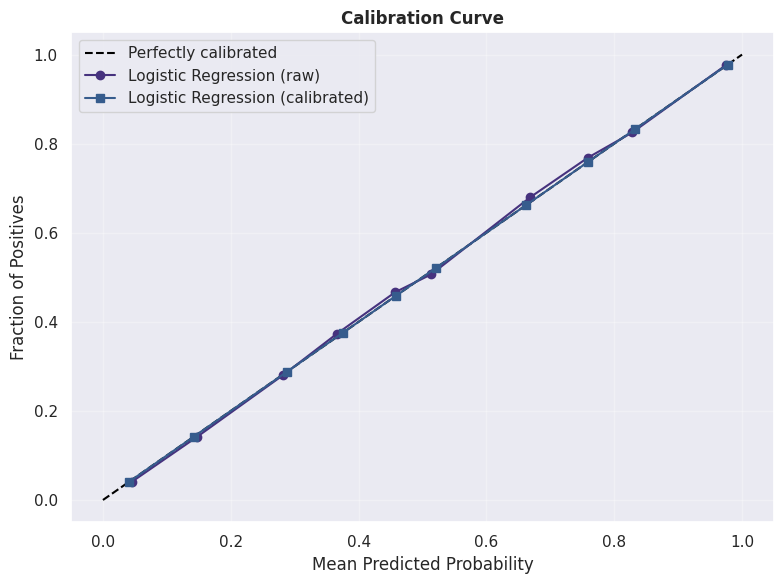

Brier score — raw: 0.1057  |  calibrated: 0.1054

Threshold chosen on validation set: 0.409
Sensitivity on val: 0.9078
Specificity on val: 0.7500
threshold.json saved.


In [11]:
print('=' * 70)
print(f'FINAL MODEL: {SEL_NAME}')
print('CALIBRATION SETUP')
print('=' * 70)

# ── Base model trained on TRAIN set ONLY (not train+val) ──
base_model = build_model(SEL_NAME, tuned_params[SEL_NAME])
base_model.fit(X_tr, y_train)
print(f'Base model fitted on X_train ({len(X_tr):,} rows).')

# ── Calibration on VALIDATION set ──
# Use FrozenEstimator if available (sklearn >= 1.8), else cv='prefit'
CAL_METHOD = 'isotonic'

if _FROZEN_AVAILABLE:
    print('Using FrozenEstimator (sklearn >= 1.8 mode).')
    cal_clf = CalibratedClassifierCV(
        FrozenEstimator(base_model),
        method=CAL_METHOD, cv='prefit'
    )
else:
    print('Using cv="prefit" (older sklearn mode).')
    cal_clf = CalibratedClassifierCV(
        base_model,
        method=CAL_METHOD, cv='prefit'
    )

cal_clf.fit(X_vl, y_val)   # calibrated on validation only
print('Calibration complete. Checking type of inner estimator:')
print(f'  type(cal_clf.calibrated_classifiers_[0].estimator) = '
      f'{type(cal_clf.calibrated_classifiers_[0].estimator).__name__}')

# ── Calibration curves ──
raw_proba  = base_model.predict_proba(X_vl)[:, 1]
cal_proba  = cal_clf.predict_proba(X_vl)[:, 1]
pt_r, pp_r = calibration_curve(y_val, raw_proba,  n_bins=10)
pt_c, pp_c = calibration_curve(y_val, cal_proba,  n_bins=10)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0,1], [0,1], 'k--', label='Perfectly calibrated')
ax.plot(pp_r, pt_r, 'o-', label=f'{SEL_NAME} (raw)')
ax.plot(pp_c, pt_c, 's-', label=f'{SEL_NAME} (calibrated)')
ax.set_xlabel('Mean Predicted Probability'); ax.set_ylabel('Fraction of Positives')
ax.set_title('Calibration Curve', fontweight='bold'); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('calibration_curve.png', dpi=150, bbox_inches='tight')
plt.show()

brier_raw = brier_score_loss(y_val, raw_proba)
brier_cal = brier_score_loss(y_val, cal_proba)
print(f'Brier score — raw: {brier_raw:.4f}  |  calibrated: {brier_cal:.4f}')

# ── Threshold selection on VALIDATION set ──
best_t    = 0.5
best_spec = 0.0
for t in np.linspace(0.01, 0.99, 200):
    preds = (cal_proba >= t).astype(int)
    if recall_score(y_val, preds, zero_division=0) >= TARGET_SENSITIVITY:
        tn_v, fp_v, fn_v, tp_v = confusion_matrix(y_val, preds).ravel()
        sp = tn_v / (tn_v + fp_v) if (tn_v + fp_v) > 0 else 0
        if sp > best_spec:
            best_spec = sp; best_t = t

THRESHOLD = float(best_t)
print(f'\nThreshold chosen on validation set: {THRESHOLD:.3f}')
print(f'Sensitivity on val: '
      f'{recall_score(y_val, (cal_proba >= THRESHOLD).astype(int)):.4f}')
print(f'Specificity on val: {best_spec:.4f}')

with open('threshold.json', 'w') as f:
    json.dump({'threshold': THRESHOLD, 'target_sensitivity': TARGET_SENSITIVITY}, f, indent=2)
print('threshold.json saved.')

In [12]:
print('=' * 70)
print('FINAL TEST SET EVALUATION  (used ONCE, only here)')
print('=' * 70)

te_proba = cal_clf.predict_proba(X_te)[:, 1]
te_pred  = (te_proba >= THRESHOLD).astype(int)

acc  = accuracy_score(y_test, te_pred)
prec = precision_score(y_test, te_pred)
rec  = recall_score(y_test, te_pred)
f1   = f1_score(y_test, te_pred)
roc  = roc_auc_score(y_test, te_proba)
mcc  = matthews_corrcoef(y_test, te_pred)
brier= brier_score_loss(y_test, te_proba)
tn, fp, fn, tp = confusion_matrix(y_test, te_pred).ravel()
spec = tn / (tn + fp)

print(f'  Threshold : {THRESHOLD:.3f}  (target sensitivity >= {TARGET_SENSITIVITY})')
print(f'  Accuracy  : {acc:.4f}')
print(f'  Precision : {prec:.4f}')
print(f'  Recall    : {rec:.4f}')
print(f'  Specificity: {spec:.4f}')
print(f'  F1        : {f1:.4f}')
print(f'  ROC-AUC   : {roc:.4f}')
print(f'  MCC       : {mcc:.4f}')
print(f'  Brier     : {brier:.4f}')

# Prevalence impact table
print('\n' + '-' * 60)
print('PREVALENCE IMPACT TABLE')
print(f'  sensitivity={rec:.4f}  specificity={spec:.4f}')
print(f"  {'Prevalence':>12}  {'Precision (PPV)':>17}  {'NPV':>8}")
print('-' * 42)
for prev in [0.001, 0.01, 0.05]:
    tp_e = rec * prev
    fp_e = (1 - spec) * (1 - prev)
    ppv  = tp_e / (tp_e + fp_e) if (tp_e + fp_e) > 0 else 0
    tn_e = spec * (1 - prev)
    fn_e = (1 - rec) * prev
    npv  = tn_e / (tn_e + fn_e) if (tn_e + fn_e) > 0 else 0
    print(f'  {prev*100:>11.1f}%  {ppv*100:>16.2f}%  {npv*100:>7.2f}%')
print('At real-world ~1% prevalence, precision drops sharply — '
      'do not use as standalone diagnosis.')

FINAL TEST SET EVALUATION  (used ONCE, only here)
  Threshold : 0.409  (target sensitivity >= 0.9)
  Accuracy  : 0.8388
  Precision : 0.8283
  Recall    : 0.9066
  Specificity: 0.7477
  F1        : 0.8657
  ROC-AUC   : 0.9267
  MCC       : 0.6693
  Brier     : 0.1053

------------------------------------------------------------
PREVALENCE IMPACT TABLE
  sensitivity=0.9066  specificity=0.7477
    Prevalence    Precision (PPV)       NPV
------------------------------------------
          0.1%              0.36%    99.99%
          1.0%              3.50%    99.87%
          5.0%             15.90%    99.35%
At real-world ~1% prevalence, precision drops sharply — do not use as standalone diagnosis.


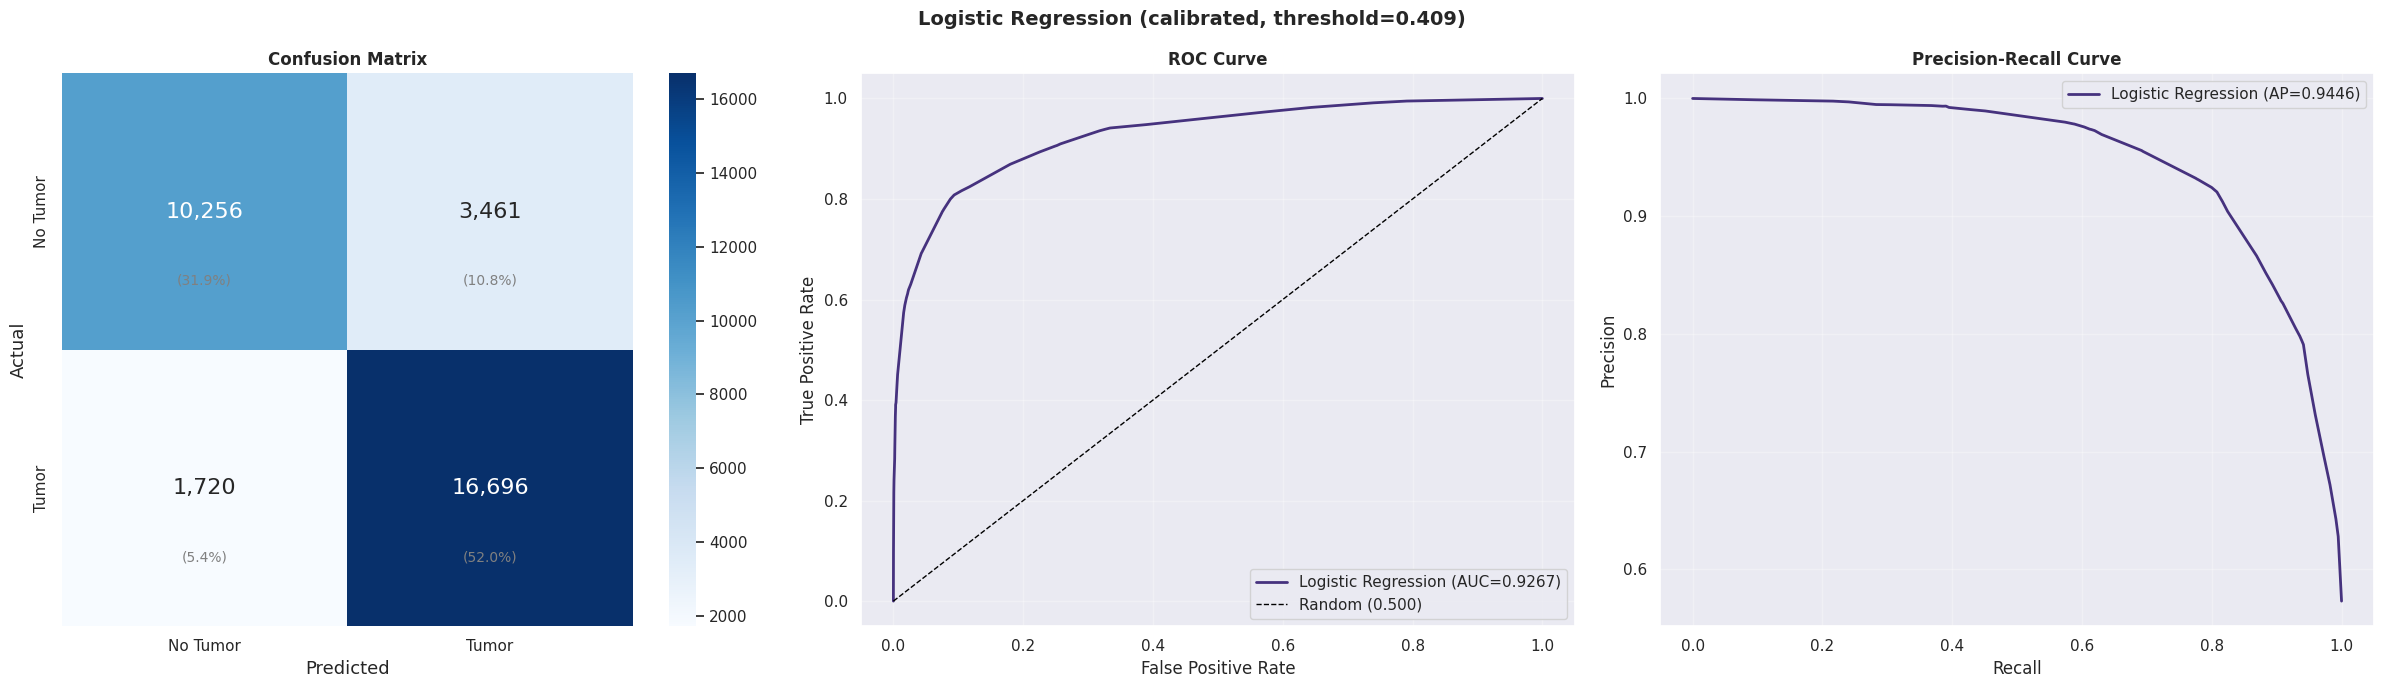

              precision    recall  f1-score   support

No Tumor (0)       0.86      0.75      0.80     13717
   Tumor (1)       0.83      0.91      0.87     18416

    accuracy                           0.84     32133
   macro avg       0.84      0.83      0.83     32133
weighted avg       0.84      0.84      0.84     32133



In [13]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
fig.suptitle(f'{SEL_NAME} (calibrated, threshold={THRESHOLD:.3f})',
             fontsize=14, fontweight='bold')

# Confusion matrix
ax = axes[0]
cm_t = confusion_matrix(y_test, te_pred)
sns.heatmap(cm_t, annot=True, fmt=',', cmap='Blues', ax=ax,
            xticklabels=['No Tumor','Tumor'], yticklabels=['No Tumor','Tumor'],
            annot_kws={'size':16})
ax.set_ylabel('Actual', fontsize=13); ax.set_xlabel('Predicted', fontsize=13)
ax.set_title('Confusion Matrix', fontweight='bold')
for i in range(2):
    for j in range(2):
        ax.text(j+0.5, i+0.75, f'({cm_t[i,j]/cm_t.sum()*100:.1f}%)',
                ha='center', va='center', fontsize=10, color='gray')

# ROC
ax = axes[1]
fpr_, tpr_, _ = roc_curve(y_test, te_proba)
ax.plot(fpr_, tpr_, lw=2, label=f'{SEL_NAME} (AUC={roc:.4f})')
ax.plot([0,1],[0,1],'k--', lw=1, label='Random (0.500)')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', fontweight='bold'); ax.legend(); ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[2]
pa, ra, _ = precision_recall_curve(y_test, te_proba)
ap = average_precision_score(y_test, te_proba)
ax.plot(ra, pa, lw=2, label=f'{SEL_NAME} (AP={ap:.4f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

print(classification_report(y_test, te_pred,
      target_names=['No Tumor (0)', 'Tumor (1)']))

Inner model type: LogisticRegression
Computing SHAP values...
TreeExplainer failed: Model type not yet supported by TreeExplainer: <class 'sklearn.linear_model._logistic.LogisticRegression'>
SHAP explainer used: Linear


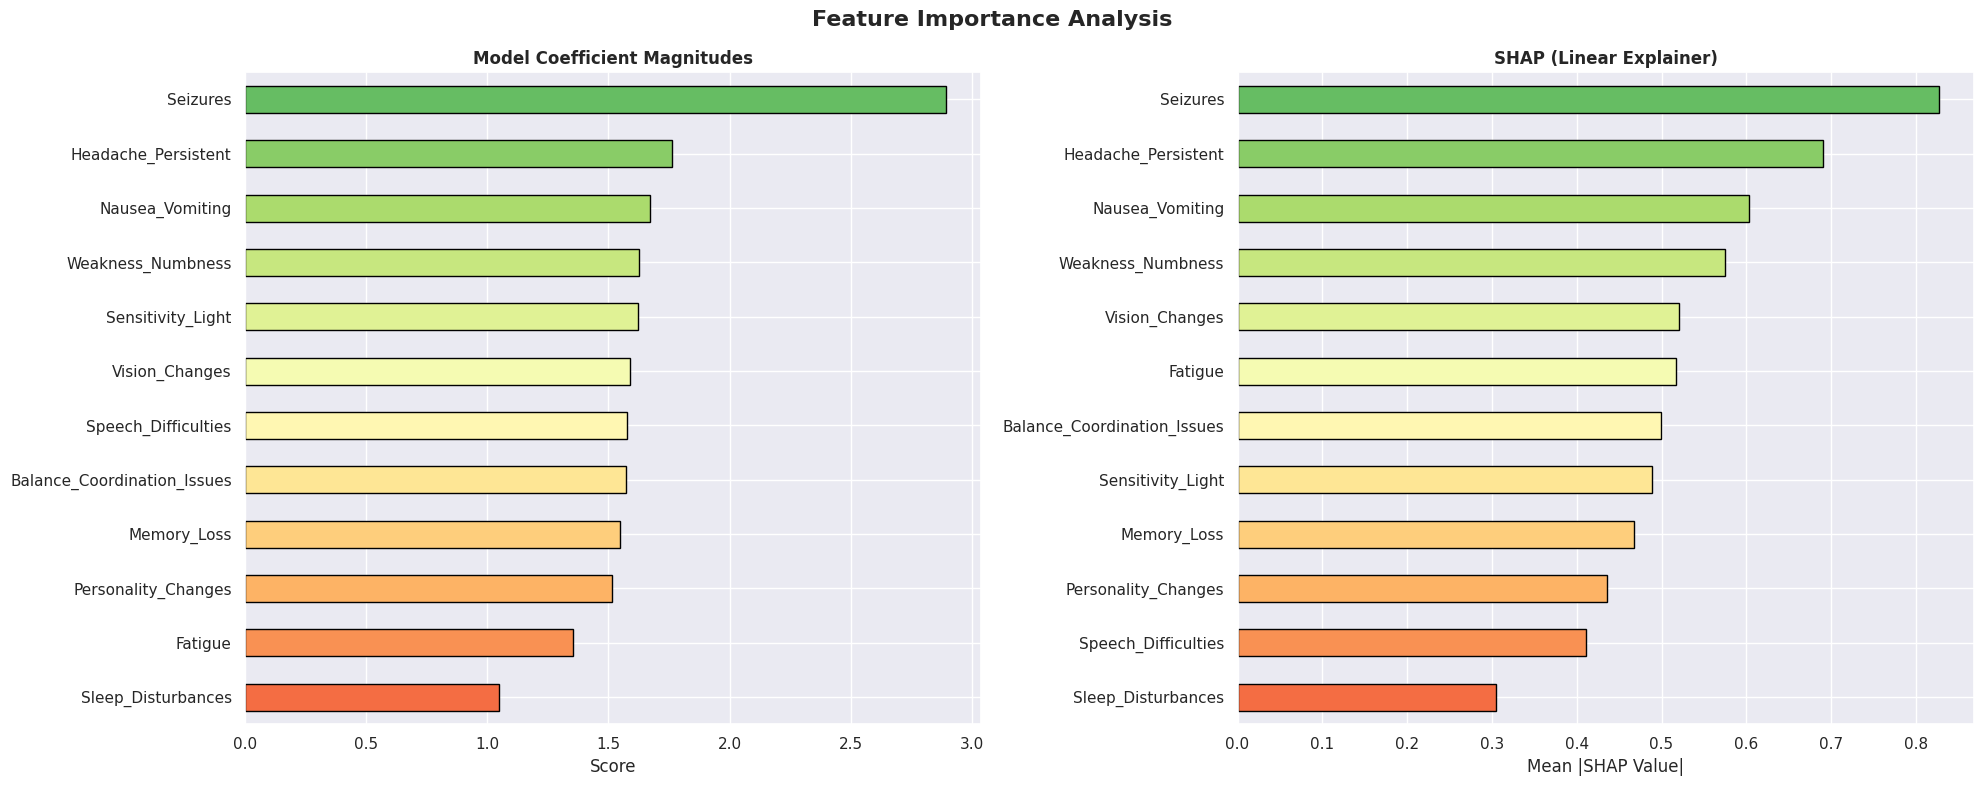

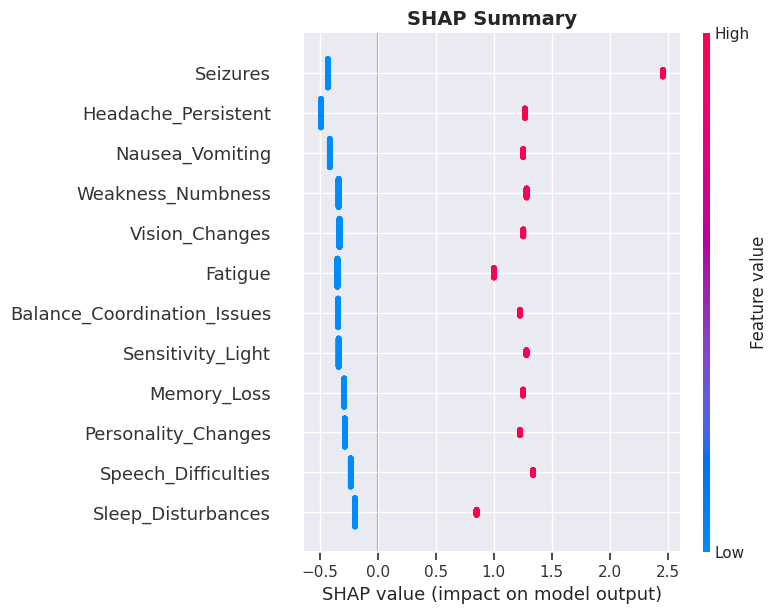


Top 5 features (SHAP):
  1. Seizures: 0.8271
  2. Headache_Persistent: 0.6904
  3. Nausea_Vomiting: 0.6031
  4. Weakness_Numbness: 0.5746
  5. Vision_Changes: 0.5211


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('Feature Importance Analysis', fontsize=16, fontweight='bold')

# ── Extract inner model safely ──
inner = cal_clf.calibrated_classifiers_[0].estimator

# FrozenEstimator wraps the real model
if _FROZEN_AVAILABLE and isinstance(inner, FrozenEstimator):
    inner = inner.estimator

print(f'Inner model type: {type(inner).__name__}')

# 1. Built-in importance / coefficients
ax = axes[0]
if hasattr(inner, 'feature_importances_'):
    imp = pd.Series(inner.feature_importances_, index=FINAL_FEATURES)
    title_s = 'Feature Importances'
elif hasattr(inner, 'coef_'):
    imp = pd.Series(np.abs(inner.coef_[0]), index=FINAL_FEATURES)
    title_s = 'Coefficient Magnitudes'
else:
    imp = pd.Series(np.zeros(len(FINAL_FEATURES)), index=FINAL_FEATURES)
    title_s = 'Not Available'

imp_s = imp.sort_values(ascending=True)
c_imp = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(imp_s)))
imp_s.plot(kind='barh', ax=ax, color=c_imp, edgecolor='black')
ax.set_title(f'Model {title_s}', fontweight='bold'); ax.set_xlabel('Score')

# 2. SHAP
ax = axes[1]
print('Computing SHAP values...')
X_shap = X_te.sample(min(500, len(X_te)), random_state=RANDOM_SEED)
explainer_type = 'None'
shap_vals = None

try:
    exp = shap.TreeExplainer(inner)
    shap_vals = exp.shap_values(X_shap)
    if isinstance(shap_vals, list): shap_vals = shap_vals[1]
    explainer_type = 'Tree'
except Exception as e:
    print(f'TreeExplainer failed: {e}')
    try:
        exp = shap.LinearExplainer(inner, X_shap)
        shap_vals = exp.shap_values(X_shap)
        if isinstance(shap_vals, list): shap_vals = shap_vals[1]
        explainer_type = 'Linear'
    except Exception as e2:
        print(f'LinearExplainer failed: {e2}')
        exp = shap.KernelExplainer(inner.predict_proba, X_shap.iloc[:50])
        shap_vals = exp.shap_values(X_shap, nsamples=50)
        if isinstance(shap_vals, list): shap_vals = shap_vals[1]
        explainer_type = 'Kernel'

print(f'SHAP explainer used: {explainer_type}')
mean_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=FINAL_FEATURES).sort_values(ascending=True)
c_shap = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(mean_shap)))
mean_shap.plot(kind='barh', ax=ax, color=c_shap, edgecolor='black')
ax.set_title(f'SHAP ({explainer_type} Explainer)', fontweight='bold')
ax.set_xlabel('Mean |SHAP Value|')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_vals, X_shap, feature_names=FINAL_FEATURES, show=False)
plt.title('SHAP Summary', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTop 5 features (SHAP):')
for i, (f, v) in enumerate(mean_shap.sort_values(ascending=False).head(5).items(), 1):
    print(f'  {i}. {f}: {v:.4f}')

Generating learning curve for final model...


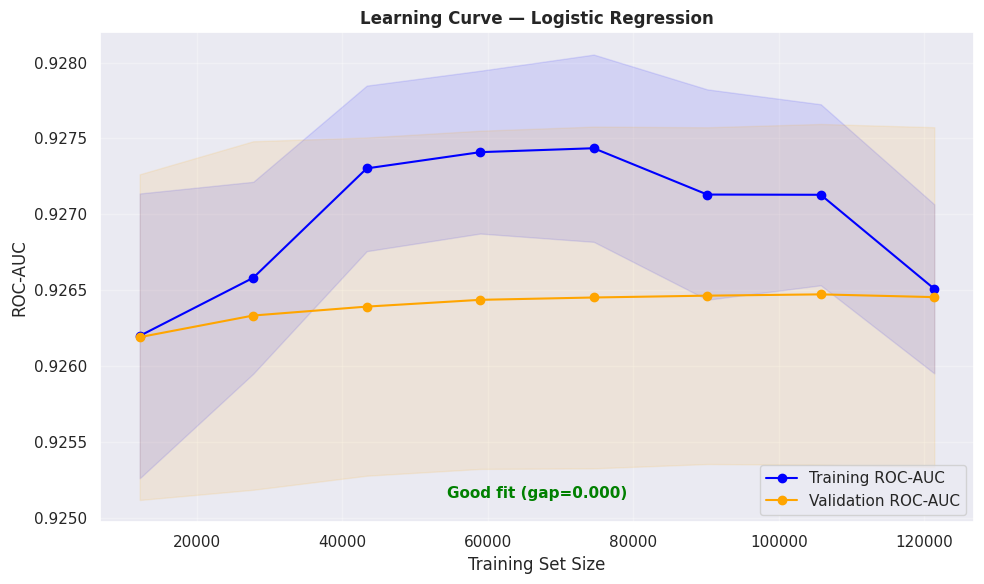

In [15]:
print('Generating learning curve for final model...')

# Clone inner model only (not calibrated wrapper)
lc_model = clone(inner)

tr_sz, tr_sc, vl_sc = learning_curve(
    lc_model, X_tv, y_trainval,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
    scoring='roc_auc', n_jobs=-1
)

tr_m = tr_sc.mean(axis=1); tr_s = tr_sc.std(axis=1)
vl_m = vl_sc.mean(axis=1); vl_s = vl_sc.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.fill_between(tr_sz, tr_m-tr_s, tr_m+tr_s, alpha=0.1, color='blue')
ax.fill_between(tr_sz, vl_m-vl_s, vl_m+vl_s, alpha=0.1, color='orange')
ax.plot(tr_sz, tr_m, 'o-', color='blue',   label='Training ROC-AUC')
ax.plot(tr_sz, vl_m, 'o-', color='orange', label='Validation ROC-AUC')
ax.set_xlabel('Training Set Size'); ax.set_ylabel('ROC-AUC')
ax.set_title(f'Learning Curve — {SEL_NAME}', fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

gap = tr_m[-1] - vl_m[-1]
clr = 'red' if gap > 0.05 else 'green'
msg = f'Overfitting (gap={gap:.3f})' if gap > 0.05 else f'Good fit (gap={gap:.3f})'
ax.text(0.5, 0.05, msg, transform=ax.transAxes,
        color=clr, fontsize=11, ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
print('=' * 70)
print('SAVING ARTEFACTS')
print('=' * 70)

joblib.dump(cal_clf, 'brain_tumor_model.pkl')

encoding_maps = {
    'Diabetes':        {'No': 0, 'Yes': 1},
    'Chronic_Illness': {'No': 0, 'Yes': 1},
    'BP_Category':     {'Normal':0,'Elevated':1,
                        'Stage 1 Hypertension':2,'Stage 2 Hypertension':3},
}
decoding_maps = {
    'Brain_Tumor_Present': {0: 'Low symptom-based risk',
                             1: 'High symptom-based risk'},
    'BP_Category': {0:'Normal',1:'Elevated',
                    2:'Stage 1 Hypertension',3:'Stage 2 Hypertension'},
}
with open('encoding_maps.json','w') as f: json.dump(encoding_maps, f, indent=2)
with open('decoding_maps.json','w') as f: json.dump(decoding_maps, f, indent=2)

model_info = {
    'model_name':         SEL_NAME,
    'chosen_feature_set': CHOSEN_FS,
    'final_features':     FINAL_FEATURES,
    'calibration_method': CAL_METHOD,
    'decision_threshold': THRESHOLD,
    'target_sensitivity': TARGET_SENSITIVITY,
    'cv_roc_auc':         tuned_cv[SEL_NAME]['roc_auc'],
    'cv_f1':              tuned_cv[SEL_NAME]['f1'],
    'test_accuracy':      float(acc),
    'test_precision':     float(prec),
    'test_recall':        float(rec),
    'test_specificity':   float(spec),
    'test_f1':            float(f1),
    'test_roc_auc':       float(roc),
    'test_mcc':           float(mcc),
    'test_brier_score':   float(brier),
    'dataset_rows_raw':   int(len(df_raw)),
    'dataset_rows_clean': int(len(df)),
    'limitations': [
        'Dataset appears synthetic: 12 symptom columns give ~0.92 ROC-AUC, which is the performance ceiling.',
        '57% tumor prevalence is far above real-world rates (~1-5%). Probabilities do not show real-world risk.',
        'BP, Chronic_Illness, and Diabetes have AUC ~0.50 — no predictive value in this dataset.',
        'Not a diagnostic tool. For informational and research purposes only.',
        'Model trained where 57% rows had a tumor — probabilities do not represent real-world risk.',
    ]
}
with open('model_info.json','w') as f: json.dump(model_info, f, indent=2)

print('Saved:')
for fn in ['brain_tumor_model.pkl','scaler_all.pkl','feature_names_all.pkl',
           'feature_names_sym.pkl','continuous_cols.pkl','threshold.json',
           'encoding_maps.json','decoding_maps.json','model_info.json']:
    print(f'  {fn}')

SAVING ARTEFACTS
Saved:
  brain_tumor_model.pkl
  scaler_all.pkl
  feature_names_all.pkl
  feature_names_sym.pkl
  continuous_cols.pkl
  threshold.json
  encoding_maps.json
  decoding_maps.json
  model_info.json


In [17]:
_CACHE = {}

def _load():
    if _CACHE: return _CACHE
    _CACHE['model']   = joblib.load('brain_tumor_model.pkl')
    _CACHE['scaler']  = joblib.load('scaler_all.pkl')
    _CACHE['cont']    = joblib.load('continuous_cols.pkl')
    with open('threshold.json') as f:   _CACHE['thresh'] = json.load(f)['threshold']
    with open('model_info.json') as f:
        mi = json.load(f)
    _CACHE['fs']   = mi['chosen_feature_set']
    _CACHE['feat'] = mi['final_features']
    return _CACHE

SYMP_KEYS = [
    'headache_persistent','nausea_vomiting','vision_changes','seizures',
    'balance_coordination_issues','speech_difficulties','memory_loss',
    'weakness_numbness','personality_changes','fatigue',
    'sensitivity_light','sleep_disturbances'
]
BP_KEYS = ('systolic_bp', 'diastolic_bp')
MISC_KEYS = ('chronic_illness', 'diabetes')

def _validate(data, chosen_fs):
    # Symptom keys mandatory
    for k in SYMP_KEYS:
        if k not in data:
            raise ValueError(f'Missing required key: {k}')
        if str(data[k]).lower() not in ('yes','no','0','1'):
            raise ValueError(f'{k!r} must be Yes/No, got {data[k]!r}')
    # BP only mandatory if full feature set is used
    if chosen_fs == 'A_all':
        for k in BP_KEYS:
            if k not in data:
                raise ValueError(f'Full feature set requires {k!r}')
            v = float(data[k])
            if not (60 <= v <= 250):
                raise ValueError(f'{k}={v} outside 60-250')

def predict_brain_tumor(patient_data: dict) -> dict:
    """
    Predict symptom-based brain tumor risk.
    Always provide all 12 symptom keys (Yes/No).
    If the full feature set was chosen, systolic_bp, diastolic_bp,
    chronic_illness, diabetes are also required.
    """
    res = _load()
    chosen_fs = res['fs']
    _validate(patient_data, chosen_fs)

    yn = lambda v: 1 if str(v).lower() in ('yes','1') else 0
    syms = [yn(patient_data[k]) for k in SYMP_KEYS]
    head, naus, vis, seiz, bal, spe, mem, weak, pers, fat, light, slp = syms

    sc   = sum(syms)
    neuro = (head + vis + seiz + spe)   / 4
    cog   = (spe  + mem + pers)          / 3
    phys  = (bal  + weak + fat)          / 3
    gi    = (naus + fat)                 / 2

    # Build feature DataFrame
    if chosen_fs == 'A_all':
        sys_bp = float(patient_data['systolic_bp'])
        dia_bp = float(patient_data['diastolic_bp'])
        map_v  = round((sys_bp + 2*dia_bp)/3, 4)
        if   sys_bp >= 140 or dia_bp >= 90: bp_cat = 3
        elif sys_bp >= 130 or dia_bp >= 80: bp_cat = 2
        elif sys_bp >= 120:                  bp_cat = 1
        else:                                bp_cat = 0
        chronic = yn(patient_data.get('chronic_illness','No'))
        diab    = yn(patient_data.get('diabetes','No'))

        row = pd.DataFrame([{
            'Chronic_Illness':chronic,'Diabetes':diab,
            'Systolic_BP':sys_bp,'Diastolic_BP':dia_bp,'MAP':map_v,'BP_Category':bp_cat,
            'Headache_Persistent':head,'Nausea_Vomiting':naus,'Vision_Changes':vis,
            'Seizures':seiz,'Balance_Coordination_Issues':bal,'Speech_Difficulties':spe,
            'Memory_Loss':mem,'Weakness_Numbness':weak,'Personality_Changes':pers,
            'Fatigue':fat,'Sensitivity_Light':light,'Sleep_Disturbances':slp,
            'Symptom_Count':sc,'Neurological_Risk_Score':neuro,
            'Cognitive_Score':cog,'Physical_Score':phys,'GI_Score':gi,
        }])
        cont = [c for c in res['cont'] if c in row.columns]
        if cont: row[cont] = res['scaler'].transform(row[cont])
        bp_labels = {0:'Normal',1:'Elevated',
                     2:'Stage 1 Hypertension',3:'Stage 2 Hypertension'}
        bp_status = bp_labels[bp_cat]
    else:
        row = pd.DataFrame([{
            'Headache_Persistent':head,'Nausea_Vomiting':naus,'Vision_Changes':vis,
            'Seizures':seiz,'Balance_Coordination_Issues':bal,'Speech_Difficulties':spe,
            'Memory_Loss':mem,'Weakness_Numbness':weak,'Personality_Changes':pers,
            'Fatigue':fat,'Sensitivity_Light':light,'Sleep_Disturbances':slp,
        }])
        bp_status = None  # BP not used in symptom-only model

    X_in = row[res['feat']]
    prob = float(res['model'].predict_proba(X_in)[0, 1])
    pred = int(prob >= res['thresh'])

    if   prob < 0.25: risk = 'Low'
    elif prob < 0.50: risk = 'Medium'
    elif prob < 0.75: risk = 'High'
    else:             risk = 'Very High'

    out = {
        'result':               'High symptom-based risk' if pred else 'Low symptom-based risk',
        'tumor_flag':           bool(pred),
        'tumor_probability':    f'{prob*100:.1f}%',
        'no_tumor_probability': f'{(1-prob)*100:.1f}%',
        'risk_level':           risk,
        'threshold_used':       f'{res["thresh"]:.3f}',
        'symptoms_detected':    sc,
        'neurological_risk':    f'{neuro*100:.0f}%',
        'cognitive_risk':       f'{cog*100:.0f}%',
        'physical_risk':        f'{phys*100:.0f}%',
        '_disclaimer': (
            'Symptom-based risk indicator only. Not a medical diagnosis. '
            'Model trained where 57% rows had a tumor — probabilities do not show real-world risk. '
            'Consult a qualified physician.'
        )
    }
    if bp_status is not None:
        out['bp_status'] = bp_status
    return out

# Quick smoke test
print(predict_brain_tumor({
    'chronic_illness':'Yes','diabetes':'No',
    'systolic_bp':145,'diastolic_bp':95,
    'headache_persistent':'Yes','nausea_vomiting':'Yes',
    'vision_changes':'Yes','seizures':'Yes',
    'balance_coordination_issues':'No','speech_difficulties':'Yes',
    'memory_loss':'Yes','weakness_numbness':'No',
    'personality_changes':'No','fatigue':'Yes',
    'sensitivity_light':'No','sleep_disturbances':'No',
}))

{'result': 'High symptom-based risk', 'tumor_flag': True, 'tumor_probability': '100.0%', 'no_tumor_probability': '0.0%', 'risk_level': 'Very High', 'threshold_used': '0.409', 'symptoms_detected': 7, 'neurological_risk': '100%', 'cognitive_risk': '67%', 'physical_risk': '33%', '_disclaimer': 'Symptom-based risk indicator only. Not a medical diagnosis. Model trained where 57% rows had a tumor — probabilities do not show real-world risk. Consult a qualified physician.'}


In [18]:
print('Inference validation on 1,000 random rows...')

sample = df.sample(min(1000, len(df)), random_state=RANDOM_SEED).reset_index(drop=True)

# Direct model predictions on CSV data
X_s_csv = sample[FINAL_FEATURES].copy().astype(float)
if CHOSEN_FS == 'A_all':
    cont = [c for c in CONTINUOUS_COLS if c in X_s_csv.columns]
    X_s_csv[cont] = scaler_all.transform(X_s_csv[cont])

direct_proba = cal_clf.predict_proba(X_s_csv)[:, 1]
direct_pred  = (direct_proba >= THRESHOLD).astype(int)

pred_errors = 0
feat_errors = 0

for i, row in sample.iterrows():
    idx = sample.index.get_loc(i)

    pd_in = {
        'chronic_illness':             'Yes' if row['Chronic_Illness']==1 else 'No',
        'diabetes':                    'Yes' if row['Diabetes']==1        else 'No',
        'systolic_bp':                 int(row['Systolic_BP']),
        'diastolic_bp':                int(row['Diastolic_BP']),
        'headache_persistent':         'Yes' if row['Headache_Persistent']==1         else 'No',
        'nausea_vomiting':             'Yes' if row['Nausea_Vomiting']==1             else 'No',
        'vision_changes':              'Yes' if row['Vision_Changes']==1              else 'No',
        'seizures':                    'Yes' if row['Seizures']==1                    else 'No',
        'balance_coordination_issues': 'Yes' if row['Balance_Coordination_Issues']==1 else 'No',
        'speech_difficulties':         'Yes' if row['Speech_Difficulties']==1         else 'No',
        'memory_loss':                 'Yes' if row['Memory_Loss']==1                 else 'No',
        'weakness_numbness':           'Yes' if row['Weakness_Numbness']==1           else 'No',
        'personality_changes':         'Yes' if row['Personality_Changes']==1         else 'No',
        'fatigue':                     'Yes' if row['Fatigue']==1                     else 'No',
        'sensitivity_light':           'Yes' if row['Sensitivity_Light']==1           else 'No',
        'sleep_disturbances':          'Yes' if row['Sleep_Disturbances']==1          else 'No',
    }

    r = predict_brain_tumor(pd_in)
    if int(r['tumor_flag']) != direct_pred[idx]:
        pred_errors += 1

    # ── Feature value assertions ──
    syms_inf = [1 if pd_in[k]=='Yes' else 0 for k in [
        'headache_persistent','nausea_vomiting','vision_changes','seizures',
        'balance_coordination_issues','speech_difficulties','memory_loss',
        'weakness_numbness','personality_changes','fatigue',
        'sensitivity_light','sleep_disturbances']]
    sc_inf   = sum(syms_inf)
    neuro_inf= (syms_inf[0]+syms_inf[2]+syms_inf[3]+syms_inf[5])/4
    cog_inf  = (syms_inf[5]+syms_inf[6]+syms_inf[8])/3
    phys_inf = (syms_inf[4]+syms_inf[7]+syms_inf[9])/3
    gi_inf   = (syms_inf[1]+syms_inf[9])/2
    sys_inf  = int(pd_in['systolic_bp'])
    dia_inf  = int(pd_in['diastolic_bp'])
    map_inf  = round((sys_inf + 2*dia_inf)/3, 4)

    if CHOSEN_FS == 'A_all':
        if row['Symptom_Count'] != sc_inf:           feat_errors += 1
        if abs(row['Neurological_Risk_Score'] - neuro_inf) > 1e-6: feat_errors += 1
        if abs(row['Cognitive_Score']  - cog_inf)  > 1e-6: feat_errors += 1
        if abs(row['Physical_Score']   - phys_inf) > 1e-6: feat_errors += 1
        if abs(row['GI_Score']         - gi_inf)   > 1e-6: feat_errors += 1
        if abs(row['MAP']              - map_inf)  > 0.01:  feat_errors += 1

print(f'Prediction mismatches: {pred_errors} / {len(sample)}')
print(f'Feature mismatches:    {feat_errors} / {len(sample)}')

assert pred_errors == 0, 'Prediction mismatch — inference pipeline inconsistency!'
if CHOSEN_FS == 'A_all':
    assert feat_errors == 0, 'Feature mismatch — formula inconsistency!'
print('Validation passed.')

Inference validation on 1,000 random rows...
Prediction mismatches: 0 / 1000
Feature mismatches:    0 / 1000
Validation passed.


In [19]:
print('=' * 70)
print('PIPELINE COMPLETE — FINAL SUMMARY')
print('=' * 70)
print(f"""
Dataset rows (raw)    : {len(df_raw):,}
Dataset rows (clean)  : {len(df):,}
Chosen feature set    : {CHOSEN_FS}  ({len(FINAL_FEATURES)} features)
Selected model        : {SEL_NAME}
Calibration           : {CAL_METHOD}
Decision threshold    : {THRESHOLD:.3f}  (sensitivity target >= {TARGET_SENSITIVITY})

TEST SET RESULTS
  Accuracy    : {acc:.4f}
  Precision   : {prec:.4f}
  Recall      : {rec:.4f}
  Specificity : {spec:.4f}
  F1          : {f1:.4f}
  ROC-AUC     : {roc:.4f}
  MCC         : {mcc:.4f}
  Brier Score : {brier:.4f}
""")

download_files = [
    'brain_tumor_model.pkl','scaler_all.pkl','feature_names_all.pkl',
    'feature_names_sym.pkl','continuous_cols.pkl','threshold.json',
    'encoding_maps.json','decoding_maps.json','model_info.json',
    'eda_overview.png','correlation_heatmap.png','calibration_curve.png',
    'model_evaluation.png','feature_importance.png',
    'shap_summary.png','learning_curves.png',
]

try:
    from google.colab import files as colab_files
    for fn in download_files:
        if os.path.exists(fn):
            colab_files.download(fn); print(f'Downloaded: {fn}')
        else:
            print(f'Not found (skip): {fn}')
except ImportError:
    print('(Not in Colab — download skipped.)')

PIPELINE COMPLETE — FINAL SUMMARY

Dataset rows (raw)    : 217,585
Dataset rows (clean)  : 214,218
Chosen feature set    : B_symptom  (12 features)
Selected model        : Logistic Regression
Calibration           : isotonic
Decision threshold    : 0.409  (sensitivity target >= 0.9)

TEST SET RESULTS
  Accuracy    : 0.8388
  Precision   : 0.8283
  Recall      : 0.9066
  Specificity : 0.7477
  F1          : 0.8657
  ROC-AUC     : 0.9267
  MCC         : 0.6693
  Brier Score : 0.1053



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: brain_tumor_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (39 outputs left out)

Downloaded: shap_summary.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: learning_curves.png
